# v1 vs v2

v1 is purely analytic, no noise. For v2, the diagonal includes a full model of the power spectrum which includes noise.

In [1]:
import sys
sys.path.append('/home/kboone/software/Galaxy_Bias/Bispectrum/Convert_Bispectrum/')

import os
import h5py
import numpy as np
import pandas as pd
import Visual_Helpers as VH
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.interpolate import interp1d as inter
from scipy.interpolate import CubicSpline as spline

import matplotlib
matplotlib.style.use('boone')

cmap = plt.get_cmap("tab10")

In [2]:
b1 = 9.8
b2 = 42.5
b3 = 51.7
bP = 1.19

In [3]:
power_dir = '/home/kboone/software/Galaxy_Bias/Bispectrum/Two_Points_Data/'
model_power_file = power_dir + 'CLASS_power_z1' # Location of power spectrum file
k_model_orig, Pk_model_orig = VH.read_power(model_power_file)
max_k_model = np.max(k_model_orig)
Pk_model_orig = Pk_model_orig * (0.2322)**2 # Normalization to z=8

P = spline(k_model_orig, Pk_model_orig, bc_type='natural')

In [4]:
def get_P(directory = '/mnt/nvme1/kboone/Data/BigFiles/Gala_8/'):
    phases = 25
    Pk = []
    for ph in np.arange(phases):
        power_file = directory + 'Gala_ph0' + '{:02d}'.format(ph) + '/Gala_256_ps.dat'
        
        df = pd.read_csv(power_file, sep=r'\s+')
        
        # Shift the header row to the left
        df.columns = np.roll(df.columns, -1)
        
        # Drop the first column (which now contains the original header)
        df = df.drop(df.columns[-1], axis=1)
        k = df['k_mean_over_bin_[h_Mpc^-1]'].to_numpy()
        N = df['N_modes'].to_numpy()
        Pk.append(df['P_bin_[h^-3_Mpc^3]'].to_numpy())
        
    Pk = np.array(Pk)
    return k, N, Pk


def get_sim_Pk(directory, abbreviation, symfactor=1):
    all_files = os.listdir(directory)
    files = np.array([file for file in all_files if 
                      file.endswith('.dat') and file.startswith(abbreviation) and '_v' in file])
    Pk = []
    for file in files:
        power_file = directory + file
        
        df = pd.read_csv(power_file, sep=r'\s+')
        
        # Shift the header row to the left
        df.columns = np.roll(df.columns, -1)
        
        # Drop the first column (which now contains the original header)
        df = df.drop(df.columns[-1], axis=1)
        k = df['k_mean_over_bin_[h_Mpc^-1]'].to_numpy()
        Pk.append(df['P_bin_[h^-3_Mpc^3]'].to_numpy())
        
    Pk = np.array(Pk)
    return Pk*symfactor

In [5]:
phases = 25
data_dir = '/mnt/nvme1/kboone/Data/BigFiles/Gala_8/'
z = 8
rescale = (8+1)/(z+1)

L = 2000
V = L**3
N_grid = 256
kF = 2*np.pi/L
kN = N_grid*np.pi/L

In [6]:
pos_root = '../../Data/Gala_z8_Positions/'

noises = np.zeros(phases, dtype=np.float64)

for ph in np.arange(phases):
    pos_file = pos_root + 'Gala_ph0' + '{:02d}'.format(ph) + '.h5'
    
    with h5py.File(pos_file, 'r') as f_:
        dset = f_['dataset']
        pos = dset[:].T
        noises[ph] = V/len(pos)

ave_noise = V / np.average(V / noises)

In [7]:
k, Nk, Pk = get_P(directory = data_dir)
std_P = np.std(Pk, axis=0, ddof=1)
std_cov = np.outer(std_P, std_P)
cov_P = np.cov(Pk.T, ddof=1)
kMax_P = kN

In [9]:
I = np.average(get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'b2b2'), axis=0)
I3 = np.average(get_sim_Pk('/mnt/nvme1/kboone/Sims/PowerSpectra/', 'b3b3'), axis=0)

In [10]:
def A_integrand(mu, k, kp):
    return P(np.sqrt(k**2 + kp**2 + 2*k*kp*mu))


def A(k, kp):
    '''
    Angular average of the k and k' (I call kp) sum.
    '''
    return 0.5 * quad(A_integrand, -1, 1, args=(k,kp))[0]

In [11]:
gaus_diag = 2*b1**4*P(k)**2/Nk
NG_diag = 4*b1**2*b2**2*P(k)*I/Nk
# noise_diag = 4*b1**2*P(k)*ave_noise/Nk + 4*b2**2*I*ave_noise/Nk + 4*b3**2*I3*ave_noise/Nk + 2*ave_noise**2/Nk
gaus_cov = np.diag(gaus_diag)
analytic_cov = np.diag(gaus_diag+NG_diag)
for i in np.arange(len(k)):
    for j in np.arange(len(k)):
        if i < j:
            continue
        K = k[i]; KP = k[j]
        AKKP = A(K,KP)
        analytic_cov[i,j] += 8*b1**2*b2**2*(P(K)**2+P(KP)**2)/V * AKKP
        analytic_cov[i,j] += 16*b1**2*b2**2*P(K)*P(KP)/V * AKKP
        analytic_cov[i,j] += 12*b1**3*b3*P(K)*P(KP)*(P(K)+P(KP))/V
        if i > j:
            analytic_cov[j,i] += 8*b1**2*b2**2*(P(K)**2+P(KP)**2)/V * AKKP
            analytic_cov[j,i] += 16*b1**2*b2**2*P(K)*P(KP)/V * AKKP
            analytic_cov[j,i] += 12*b1**3*b3*P(K)*P(KP)*(P(K)+P(KP))/V
        # analytic_cov[i,j] += 2*ave_noise**2*b1**2/V*(P(K)+P(KP)+AKKP)
        # analytic_cov[i,j] += 8*ave_noise*b1**2*b2/V*((P(K)+P(KP))*AKKP + P(K)*P(KP))
# analytic_cov += ave_noise**3 / V

In [48]:
diag_comp = 2*(b1**2*P(k) + b2**2*I + b3**2*I3 + bP*np.average(noises))**2 / Nk
analytic_cov = np.diag(diag_comp)
for i in np.arange(len(k)):
    for j in np.arange(len(k)):
        if i < j:
            continue
        K = k[i]; KP = k[j]
        AKKP = A(K,KP)
        analytic_cov[i,j] += 8*b1**2*b2**2*(P(K)**2+P(KP)**2)/V * AKKP
        analytic_cov[i,j] += 16*b1**2*b2**2*P(K)*P(KP)/V * AKKP
        analytic_cov[i,j] += 12*b1**3*b3*P(K)*P(KP)*(P(K)+P(KP))/V
        if i > j:
            analytic_cov[j,i] += 8*b1**2*b2**2*(P(K)**2+P(KP)**2)/V * AKKP
            analytic_cov[j,i] += 16*b1**2*b2**2*P(K)*P(KP)/V * AKKP
            analytic_cov[j,i] += 12*b1**3*b3*P(K)*P(KP)*(P(K)+P(KP))/V

np.save('Power_Cov_v2.npy', analytic_cov)

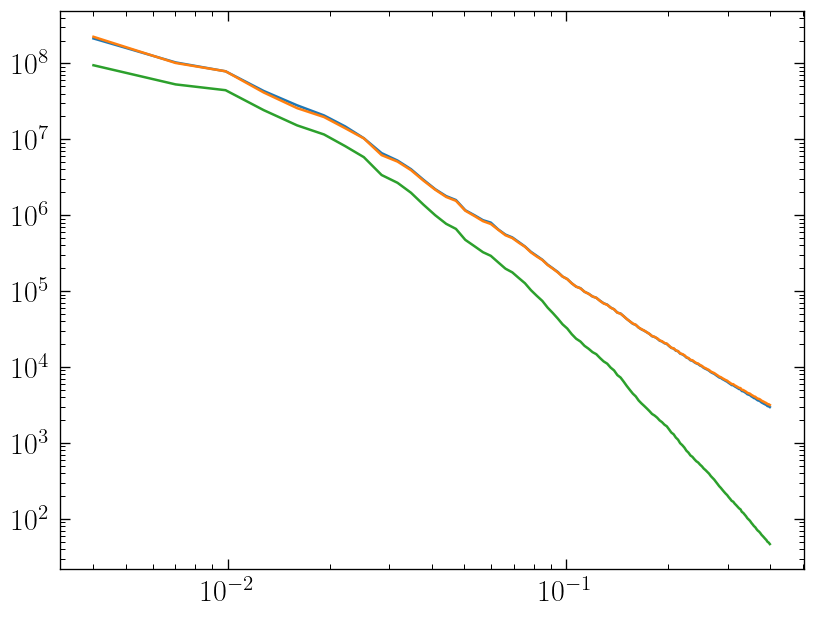

In [51]:
plt.figure(dpi = 120)
plt.loglog(k, 2*np.average(Pk, axis=0)**2/Nk)
plt.loglog(k, diag_comp)
plt.loglog(k, gaus_diag+NG_diag)
plt.show()

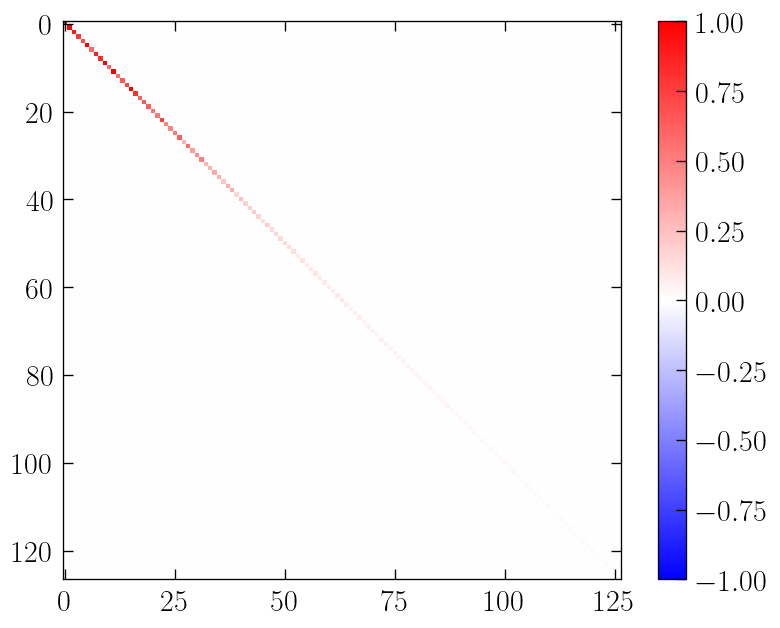

In [49]:
plt.figure(dpi = 120)
plt.imshow((analytic_cov)/std_cov, cmap='bwr', vmin=-1, vmax=1)
plt.colorbar()
plt.show()

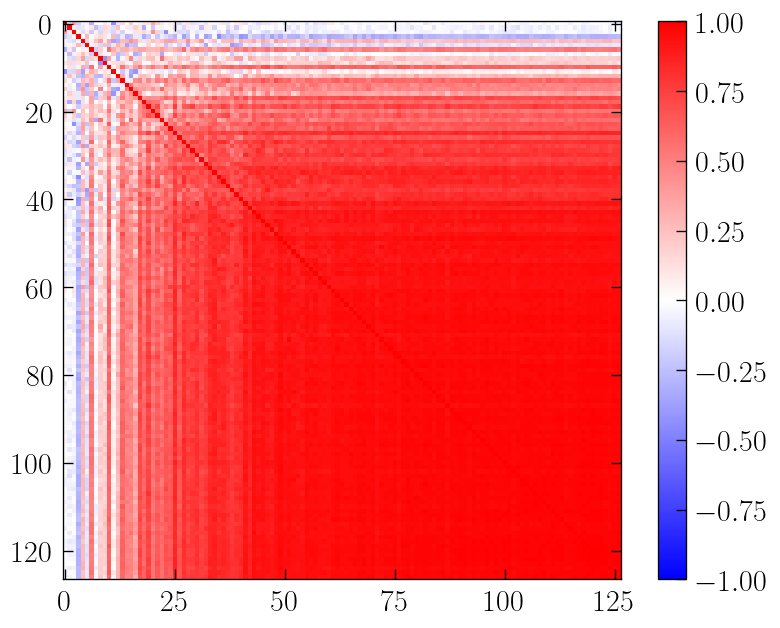

In [13]:
plt.figure(dpi = 120)
plt.imshow(cov_P/std_cov, cmap='bwr', vmin=-1, vmax=1)
plt.colorbar()
plt.show()

In [14]:
# np.save('Power_Cov.npy', analytic_cov)